# Fase 1: Ottimizzazione e Addestramento del Random Survival Forest

Questo notebook è dedicato alla ricerca dei migliori iperparametri per il nostro modello di analisi di sopravvivenza. Poiché l'addestramento di foreste casuali su dati complessi può essere computazionalmente pesante, abbiamo separato questa fase. L'obiettivo qui non è analizzare i risultati, ma **trovare la configurazione ottimale e salvare il modello**.



## Obiettivi di questo script:
1. **Preparazione dei Dati per `sksurv`**: Il pacchetto `scikit-survival` richiede che la variabile target (y) sia un array strutturato contenente lo stato dell'evento (booleano) e il tempo di follow-up.
2. **Train/Test Split**: Dividiamo il dataset tenendo da parte il 25% dei dati. **Nota bene:** Il `random_state=20` e la stratificazione sull'evento sono fondamentali per mantenere lo split identico nella fase di valutazione.
3. **Ricerca degli Iperparametri (Hyperparameter Tuning)**: Invece di usare i parametri di default, utilizziamo una `RandomizedSearchCV`. Questo metodo proverà 50 combinazioni casuali (su 5-fold cross-validation) di vari parametri:
   - `n_estimators`: Numero di alberi nella foresta.
   - `max_depth` e `min_samples_leaf`: Controllano la grandezza degli alberi per evitare l'overfitting.
   - `max_features`: Quante variabili considerare ad ogni split.
4. **Salvataggio del Modello**: Una volta trovato il "modello vincitore", lo "congeliamo" e lo salviamo su disco in formato `.pkl` usando la libreria `joblib`. In questo modo, le analisi future saranno istantanee.

In [ ]:
import pandas as pd
import joblib
from sksurv.util import Surv
from sksurv.ensemble import RandomSurvivalForest
from sklearn.model_selection import train_test_split, RandomizedSearchCV

df_clean = pd.read_csv('data/dataset_cleaned.csv')

col_tempo = "follow_ups.days_to_follow_up"
col_evento = "demographic.vital_status_DEAD"

# Creazione y e X
evento_bool = df_clean[col_evento].astype(bool)
y = Surv.from_arrays(event=evento_bool, time=df_clean[col_tempo])
X = df_clean.drop(columns=[col_tempo, col_evento])

# Split
random_state = 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=random_state,
    stratify=df_clean[col_evento]
)

# Parametri da testare
param_distributions = {
    "n_estimators": [200, 500, 1000],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [5, 10, 20, 30],
    "min_samples_leaf": [5, 10, 20, 40],
    "max_features": ["sqrt", "log2", None],
}

rsf_base = RandomSurvivalForest(random_state=random_state, n_jobs=-1)

print("Inizio ottimizzazione (potrebbe richiedere qualche minuto)...")
search = RandomizedSearchCV(
    rsf_base,
    param_distributions,
    n_iter=50,
    n_jobs=-1,
    cv=5,
    random_state=random_state,
    verbose=1
)

search.fit(X_train, y_train)

print(f"Migliori parametri trovati: {search.best_params_}")

# Salvataggio del modello migliore su disco
modello_ottimizzato = search.best_estimator_
joblib.dump(modello_ottimizzato, 'models/rsf_model.pkl')
print("Modello salvato con successo come 'rsf_model.pkl'")


# Fase 2: Valutazione del Modello e Interpretazione Clinica

In questo notebook raccogliamo i frutti dell'addestramento. Caricheremo il modello ottimizzato precedentemente salvato ed eseguiremo tutte le analisi di performance e interpretabilità, senza dover aspettare i tempi del training.

## Obiettivi di questo script:

### 1. Replicare l'Ambiente
Per valutare correttamente il modello sul Test Set, dobbiamo ricreare l'esatta divisione Train/Test usata in fase di ottimizzazione (ecco perché riutilizziamo `random_state=20`). Successivamente, ricarichiamo il file `.pkl` del modello dalla cartella `models/`.

### 2. Metriche di Valutazione Globali
- **C-index (Indice di Concordanza di Harrell)**: È l'equivalente dell'AUC-ROC per l'analisi di sopravvivenza. Indica quanto bene il modello ordina i pazienti (chi ha un rischio maggiore ha effettivamente l'evento prima?). Un valore vicino a 1 è perfetto, 0.5 equivale al caso.
- **Integrated Brier Score (IBS)**: Misura l'accuratezza (calibrazione) delle probabilità predette nel tempo. Un valore più basso (più vicino a 0) indica predizioni più precise.

### 3. AUC Cumulativa Dinamica (Time-dependent AUC)
Oltre alle metriche globali, valutiamo la capacità predittiva del modello a **scadenze temporali fisse (es. 1, 3 e 5 anni)**. Poiché il nostro dataset mappa il follow-up in giorni, convertiamo questi traguardi (365, 1095 e 1825 giorni). Questo ci permette di monitorare come "decade" il potere predittivo del modello passando dal breve al lungo termine.

### 4. Permutation Feature Importance
Quali variabili cliniche/demografiche guidano le decisioni del modello? Rimescoliamo (permutiamo) casualmente una variabile alla volta e vediamo quanto peggiora il C-index. Se peggiora molto, la variabile è cruciale. Visualizzeremo le Top 15 in un grafico a boxplot per identificare i driver di rischio (es. parametri N, metastasi, età).

### 5. Validazione Clinica e Stratificazione del Rischio
Questa è la parte più "pratica" e vicina al mondo reale clinico:
- Calcoliamo un **Risk Score** per ogni paziente del Test Set.
- Usiamo la mediana di questi punteggi per dividere i pazienti in due coorti: **Alto Rischio** e **Basso Rischio**.
- Disegniamo le curve di sopravvivenza medie predette per questi due gruppi. Ci aspettiamo che il gruppo ad alto rischio mostri un crollo della probabilità di sopravvivenza molto più rapido e netto rispetto a quello a basso rischio.

Caricamento del modello...
Modello caricato con successo!
C-index: 0.72132
Integrated Brier Score (IBS): 0.18808
Calcolo dell'importanza delle variabili in corso...


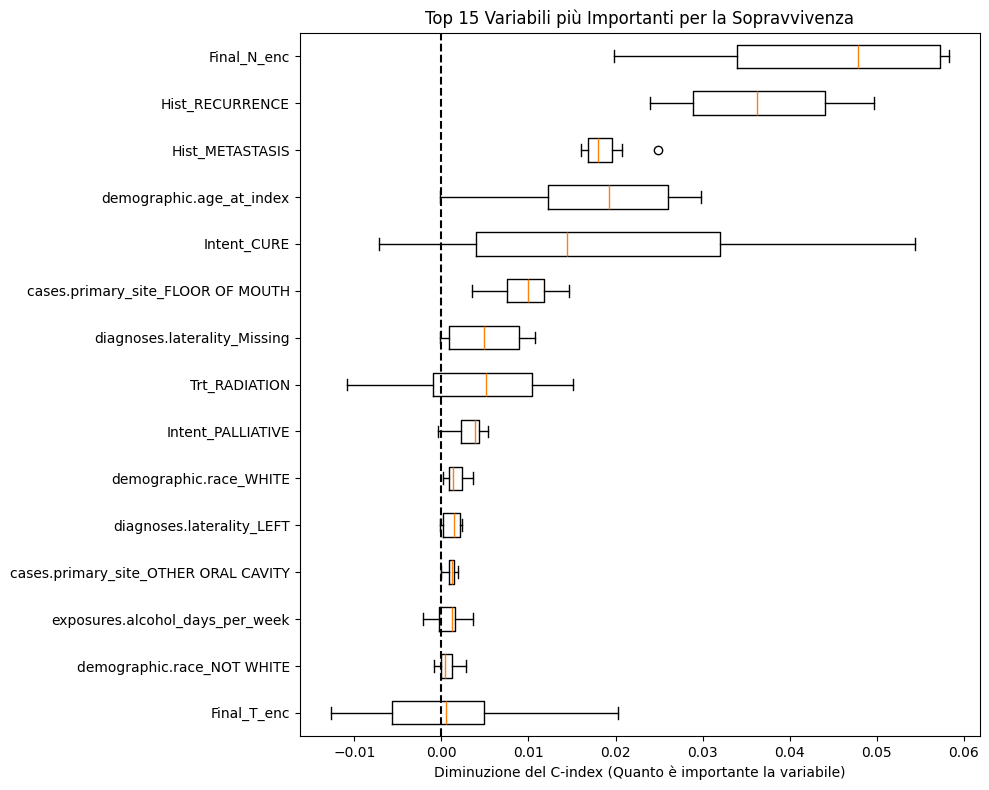

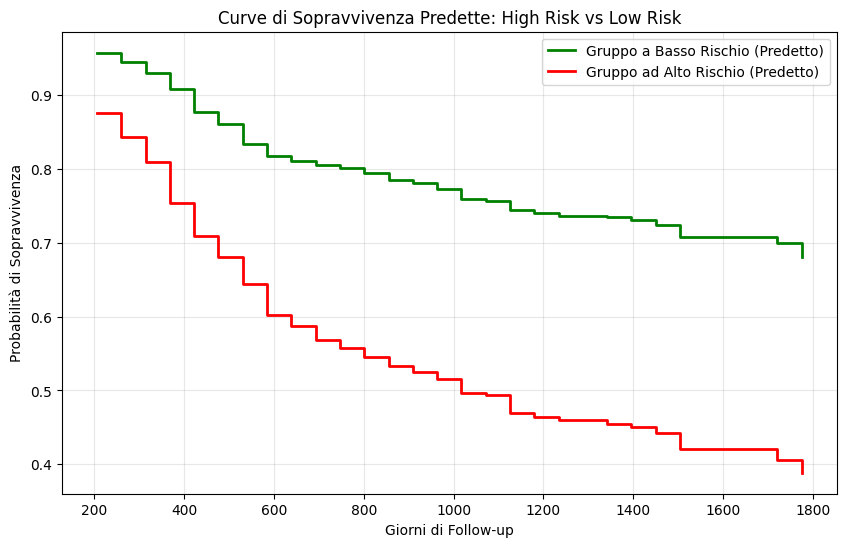


Calcolo Time-dependent AUC in corso...
--- Risultati Time-dependent AUC ---
AUC a 1 Anno/i (365 gg): 0.78485
AUC a 3 Anno/i (1095 gg): 0.67505
AUC a 5 Anno/i (1825 gg): 0.60945
Mean AUC: 0.69325



In [8]:
import pandas as pd
import numpy as np
import joblib
from matplotlib import pyplot as plt
from sksurv.util import Surv
from sksurv.metrics import integrated_brier_score
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sksurv.metrics import cumulative_dynamic_auc

# 1. Caricamento Dati
df_clean = pd.read_csv('data/dataset_cleaned.csv')

col_tempo = "follow_ups.days_to_follow_up"
col_evento = "demographic.vital_status_DEAD"

evento_bool = df_clean[col_evento].astype(bool)
y = Surv.from_arrays(event=evento_bool, time=df_clean[col_tempo])
X = df_clean.drop(columns=[col_tempo, col_evento])

# IMPORTANTE: Lo split deve essere IDENTICO a quello dell'ottimizzazione
random_state = 20
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=random_state,
    stratify=df_clean[col_evento]
)

# 2. Caricamento Modello Ottimizzato
print("Caricamento del modello...")
rsf = joblib.load('models/rsf_model.pkl')
print("Modello caricato con successo!")

# ==============================================================================
# 3. Valutazione: Score e Brier Score
# ==============================================================================
c_index = rsf.score(X_test, y_test)
print(f"C-index: {c_index:.5f}")

lower_bound = np.percentile(y_test['time'], 10)
upper_bound = np.percentile(y_test['time'], 90)
times = np.linspace(lower_bound, upper_bound, 15)

surv_funcs = rsf.predict_survival_function(X_test)
preds = np.vstack([fn(times) for fn in surv_funcs])

ibs = integrated_brier_score(y_train, y_test, preds, times)
print(f"Integrated Brier Score (IBS): {ibs:.5f}")

# ==============================================================================
# 4. Importanza Variabili
# ==============================================================================
print("Calcolo dell'importanza delle variabili in corso...")
result = permutation_importance(
    rsf, X_test, y_test, n_repeats=10, random_state=random_state, n_jobs=-1
)

perm_sorted_idx = result.importances_mean.argsort()
top_n = 15
top_idx = perm_sorted_idx[-top_n:]

plt.figure(figsize=(10, 8))
plt.boxplot(
    result.importances[top_idx].T,
    vert=False,
    tick_labels=X_test.columns[top_idx]
)
plt.xlabel("Diminuzione del C-index (Quanto è importante la variabile)")
plt.title(f"Top {top_n} Variabili più Importanti per la Sopravvivenza")
plt.axvline(x=0, color="k", linestyle="--")
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. Validazione Clinica: Stratificazione del Rischio
# ==============================================================================
risk_scores = rsf.predict(X_test)
median_risk = np.median(risk_scores)

mask_high_risk = risk_scores > median_risk
mask_low_risk = risk_scores <= median_risk

surv_funcs_high = rsf.predict_survival_function(X_test[mask_high_risk])
surv_funcs_low = rsf.predict_survival_function(X_test[mask_low_risk])

times_plot = np.linspace(lower_bound, upper_bound, 30)

mean_surv_high = np.mean(np.vstack([fn(times_plot) for fn in surv_funcs_high]), axis=0)
mean_surv_low = np.mean(np.vstack([fn(times_plot) for fn in surv_funcs_low]), axis=0)

plt.figure(figsize=(10, 6))
plt.step(times_plot, mean_surv_low, where="post", label="Gruppo a Basso Rischio (Predetto)", color="green", lw=2)
plt.step(times_plot, mean_surv_high, where="post", label="Gruppo ad Alto Rischio (Predetto)", color="red", lw=2)

plt.title("Curve di Sopravvivenza Predette: High Risk vs Low Risk")
plt.ylabel("Probabilità di Sopravvivenza")
plt.xlabel("Giorni di Follow-up")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ==============================================================================
# X. AUC Cumulativa Dinamica (Time-dependent AUC a 1, 3 e 5 anni)
# ==============================================================================
print("\nCalcolo Time-dependent AUC in corso...")

# Convertiamo gli anni in giorni
tempi_anni = [1, 3, 5]
tempi_giorni = np.array([365, 1095, 1825])

# Controllo di sicurezza: scikit-survival va in errore se chiediamo un tempo
# che supera il massimo (o è inferiore al minimo) tempo registrato nel test set.
min_time = y_test['time'].min()
max_time = y_test['time'].max()

tempi_validi = []
etichette_valide = []

for t_giorni, t_anni in zip(tempi_giorni, tempi_anni):
    if min_time < t_giorni < max_time:
        tempi_validi.append(t_giorni)
        etichette_valide.append(f"{t_anni} Anno/i")
    else:
        print(f"Attenzione: Impossibile calcolare AUC a {t_anni} anni ({t_giorni} gg). "
              f"Fuori dal range del Test Set ({min_time:.0f} - {max_time:.0f} gg).")

if tempi_validi:
    # Calcolo dell'AUC ai tempi specificati
    # usiamo i risk_scores già calcolati nella Sezione 5
    auc_values, mean_auc = cumulative_dynamic_auc(
        y_train, y_test, risk_scores, tempi_validi
    )

    print("--- Risultati Time-dependent AUC ---")
    for label, t_gg, auc in zip(etichette_valide, tempi_validi, auc_values):
        print(f"AUC a {label} ({t_gg} gg): {auc:.5f}")
    print(f"Mean AUC: {mean_auc:.5f}\n")